In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../..")

# clock/02 — condition-dataset gaze

Inspect the condition-checking clock results built by
`scripts/clock/build_condition_data.py` (generation + oracle labels + attention)
and scored by `scripts/clock/score_condition_heads.py`.

1. Load one sample + its oracle label and verify generation/labeling worked
   (label viz copied from `clock/01_data.ipynb`).
2. Load aggregated head scores, pick the top-50 step-lookback heads, and show the
   (value-weighted) attention for them on a demo sample
   (viz adapted from `clock/17_clock_multi_attn.ipynb`).

The full model is loaded so §3 can run live generations; §1/§2 work off cached results.

In [2]:
import os
import json
import logging

import numpy as np

from src.utils import env_utils, logging_utils

logging_utils.configure(level=logging.INFO)

# ── config ────────────────────────────────────────────────────────────────────
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
MODEL_SHORT = MODEL_NAME.split("/")[-1]
VERSION = "conditions"

CACHE_ROOT = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR, "multistep_clock", VERSION, MODEL_SHORT
)
print(f"cache root: {CACHE_ROOT}")
assert os.path.isdir(CACHE_ROOT), CACHE_ROOT

# Full model — §1/§2 only need the tokenizer, but §3 runs live generations.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0,1,2,3,4,6,7")
import torch
from src.models import ModelandTokenizer

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
tok = mt.tokenizer
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")

cache root: /disk/u/arnab/Codes/Projects/goals/results/multistep_clock/conditions/Qwen2.5-Coder-32B-Instruct
2026-06-09 15:01:26 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-06-09 15:01:26 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-09 15:01:26 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-06-09 15:01:26 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-09 15:01:26 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f7

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-06-09 15:01:48 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-09 15:01:48 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-06-09 15:01:48 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120, n_heads=40


## 1. Load a sample + its oracle label

Reconstruct the `LabeledGeneration` from `labels.json` (written by the build
script) and render the spec-span ↔ code-span coloring. Each condition gets a
color shared between its spec text in the prompt and the code that implements it.

In [3]:
from rich.console import Console
from rich.theme import Theme
from rich.text import Text
from rich.table import Table

from src.goals.multistep_label import LabeledGeneration

console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)


def load_labeled(sample_name, modularity):
    base = os.path.join(CACHE_ROOT, modularity, sample_name)
    with open(os.path.join(base, "labels.json")) as f:
        lab = LabeledGeneration.from_dict(json.load(f))
    with open(os.path.join(base, "completion.json")) as f:
        comp = json.load(f)
    return lab, comp


PALETTE = ["green", "cyan", "magenta", "yellow", "blue", "bright_red",
           "bright_cyan", "bright_magenta", "bright_green"]
def _vis(s): return s.replace("\n", "↵\n").replace("\t", "⇥")


def render_oracle_labels(lab):
    combined = lab.full_prompt + lab.generation
    enc = tok(combined, return_offsets_mapping=True, add_special_tokens=False)
    ids = enc["input_ids"]; offs = [tuple(p) for p in enc["offset_mapping"]]
    char_off = len(lab.full_prompt)
    gen_start = next(j for j, (a, b) in enumerate(offs) if a >= char_off and b > a)
    prompt_step, gen_step, seg_start = {}, {}, {}
    for i, sl in enumerate(lab.labels):
        if sl.prompt_token_range:
            for t in range(*sl.prompt_token_range): prompt_step[t] = i
        if sl.gen_token_range:
            for t in range(*sl.gen_token_range): gen_step[t] = i
            seg_start.setdefault(sl.gen_token_range[0], i)
    sty = lambda i: f"black on {PALETTE[i % len(PALETTE)]}"
    rich_print(f"[bold]{lab.sample_name}[/bold]   (each condition = a color; spec span + code span share it)")
    txt = Text()
    for t in range(len(ids)):
        if t == gen_start:
            txt.append("\n" + "─" * 28 + " GENERATION " + "─" * 28 + "\n", style="bold grey42")
        if t in seg_start:
            txt.append(f"\n┌── cond {seg_start[t]} ──\n", style="bold yellow")
        s = _vis(tok.decode([ids[t]]))
        i = prompt_step.get(t) if t < gen_start else gen_step.get(t)
        base = "grey42" if t < gen_start else "grey58"
        txt.append(s, style=(sty(i) if i is not None else base))
    console.print(txt)
    tb = Table(title="oracle step labels", show_lines=True)
    for col, w in [("cond", 4), ("condition", 34), ("prompt tok", 12),
                   ("gen lines", 10), ("gen tok", 12), ("gen_code", 40), ("reasoning", 36)]:
        tb.add_column(col, overflow="fold", max_width=w)
    for i, sl in enumerate(lab.labels):
        tb.add_row(str(i), sl.step_text, str(sl.prompt_token_range), str(sl.gen_line_range),
                   str(sl.gen_token_range), _vis(sl.gen_code), sl.reasoning)
    console.print(tb)

In [4]:
### ---- pick a sample to inspect ----
DEMO_SAMPLE = "cond_0001"
DEMO_MODULARITY = "monolithic"     # "modular" | "monolithic"
### -------------------------------------
lab, comp = load_labeled(DEMO_SAMPLE, DEMO_MODULARITY)
print(f"{comp['sample_name']}  lang={comp['lang']}  modularity={comp['modularity']}  "
      f"({len(lab.labels)} conditions)")
render_oracle_labels(lab)

cond_0001__python__monolithic  lang=python  modularity=monolithic  (3 conditions)


cond_0001__python__monolithic   (each condition = a color; spec span + code span share it)

<|im_start|>system↵
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>↵
<|im_start|>user↵
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:↵
↵
1. n is between 0 and 100 (inclusive)↵
2. n is odd↵
3. n is a perfect square↵
↵
For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.↵
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.↵
Do not include any comments in your code.<|im_end|>↵
<|im_start|>assistant↵
<code>↵
def check_conditions(n: int):↵

──────────────────────────── GENERATION ────────────────────────────

┌── cond 0 ──
    a = 0 <= n <= 100↵

┌── cond 1 ──
    b = n % 2 != 0↵

┌── cond 2 ──
    c = int(n**0.5)**2 == n↵
    print(f"Condition 1: {a}, Condition 2: {b}, Condition 3: {c}, All: {a and b and c}")↵
</code>

                                                oracle step labels                                                 
┏━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ cond ┃ condition            ┃ prompt tok ┃ gen lines ┃ gen tok    ┃ gen_code             ┃ reasoning            ┃
┡━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ 0    │ n is between 0 and   │ (70, 83)   │ (1, 1)    │ (226, 239) │     a = 0 <= n <=    │ Line 1 checks that n │
│      │ 100 (inclusive)      │            │           │            │ 100↵                 │ is between 0 and 100 │
│      │                      │            │           │            │                      │ inclusive.           │
├──────┼──────────────────────┼────────────┼───────────┼────────────┼──────────────────────┼──────────────────────┤
│ 1    │ n is odd             │ (85, 88)   │ (2, 2)    │ (239, 250) │     b = n % 2 != 0↵  │ Line 2 checks that n │
│      │                      │            │           │            │                      │ is odd by verifying  │
│      │                      │            │           │            │                      │ n % 2 != 0.          │
├──────┼──────────────────────┼────────────┼───────────┼────────────┼──────────────────────┼──────────────────────┤
│ 2    │ n is a perfect       │ (91, 96)   │ (3, 3)    │ (250, 264) │     c =              │ Line 3 checks that n │
│      │ square               │            │           │            │ int(n**0.5)**2 == n↵ │ is a perfect square  │
│      │                      │            │           │            │                      │ by comparing         │
│      │                      │            │           │            │                      │ int(n**0.5)**2 to n. │
└──────┴──────────────────────┴────────────┴───────────┴────────────┴──────────────────────┴──────────────────────┘

## 2. Aggregated head scores → top-50 heads → attention viz

Load `head_scores/aggregated.npz` (built by `score_condition_heads.py`,
`q_span=15`, `compare_with=mean`, key tokens = `id_substrs`), plot the
step-lookback heatmaps, then take the top-50 heads and show the value-weighted
attention for them on a demo sample. The cached attention was extracted with
`value_weighted=True`, so each (q, k) weight already reflects ‖v_k‖.

loaded /disk/u/arnab/Codes/Projects/goals/results/multistep_clock/conditions/Qwen2.5-Coder-32B-Instruct/head_scores/qspan-15_cmp-mean
  config: q_span=15  compare_with=mean
  modular     mean=1.406  max=3.638
  monolithic  mean=1.352  max=3.306
  combined    mean=1.383  max=3.478
selected 200 7.81% heads via topk on 'combined' (top 200)


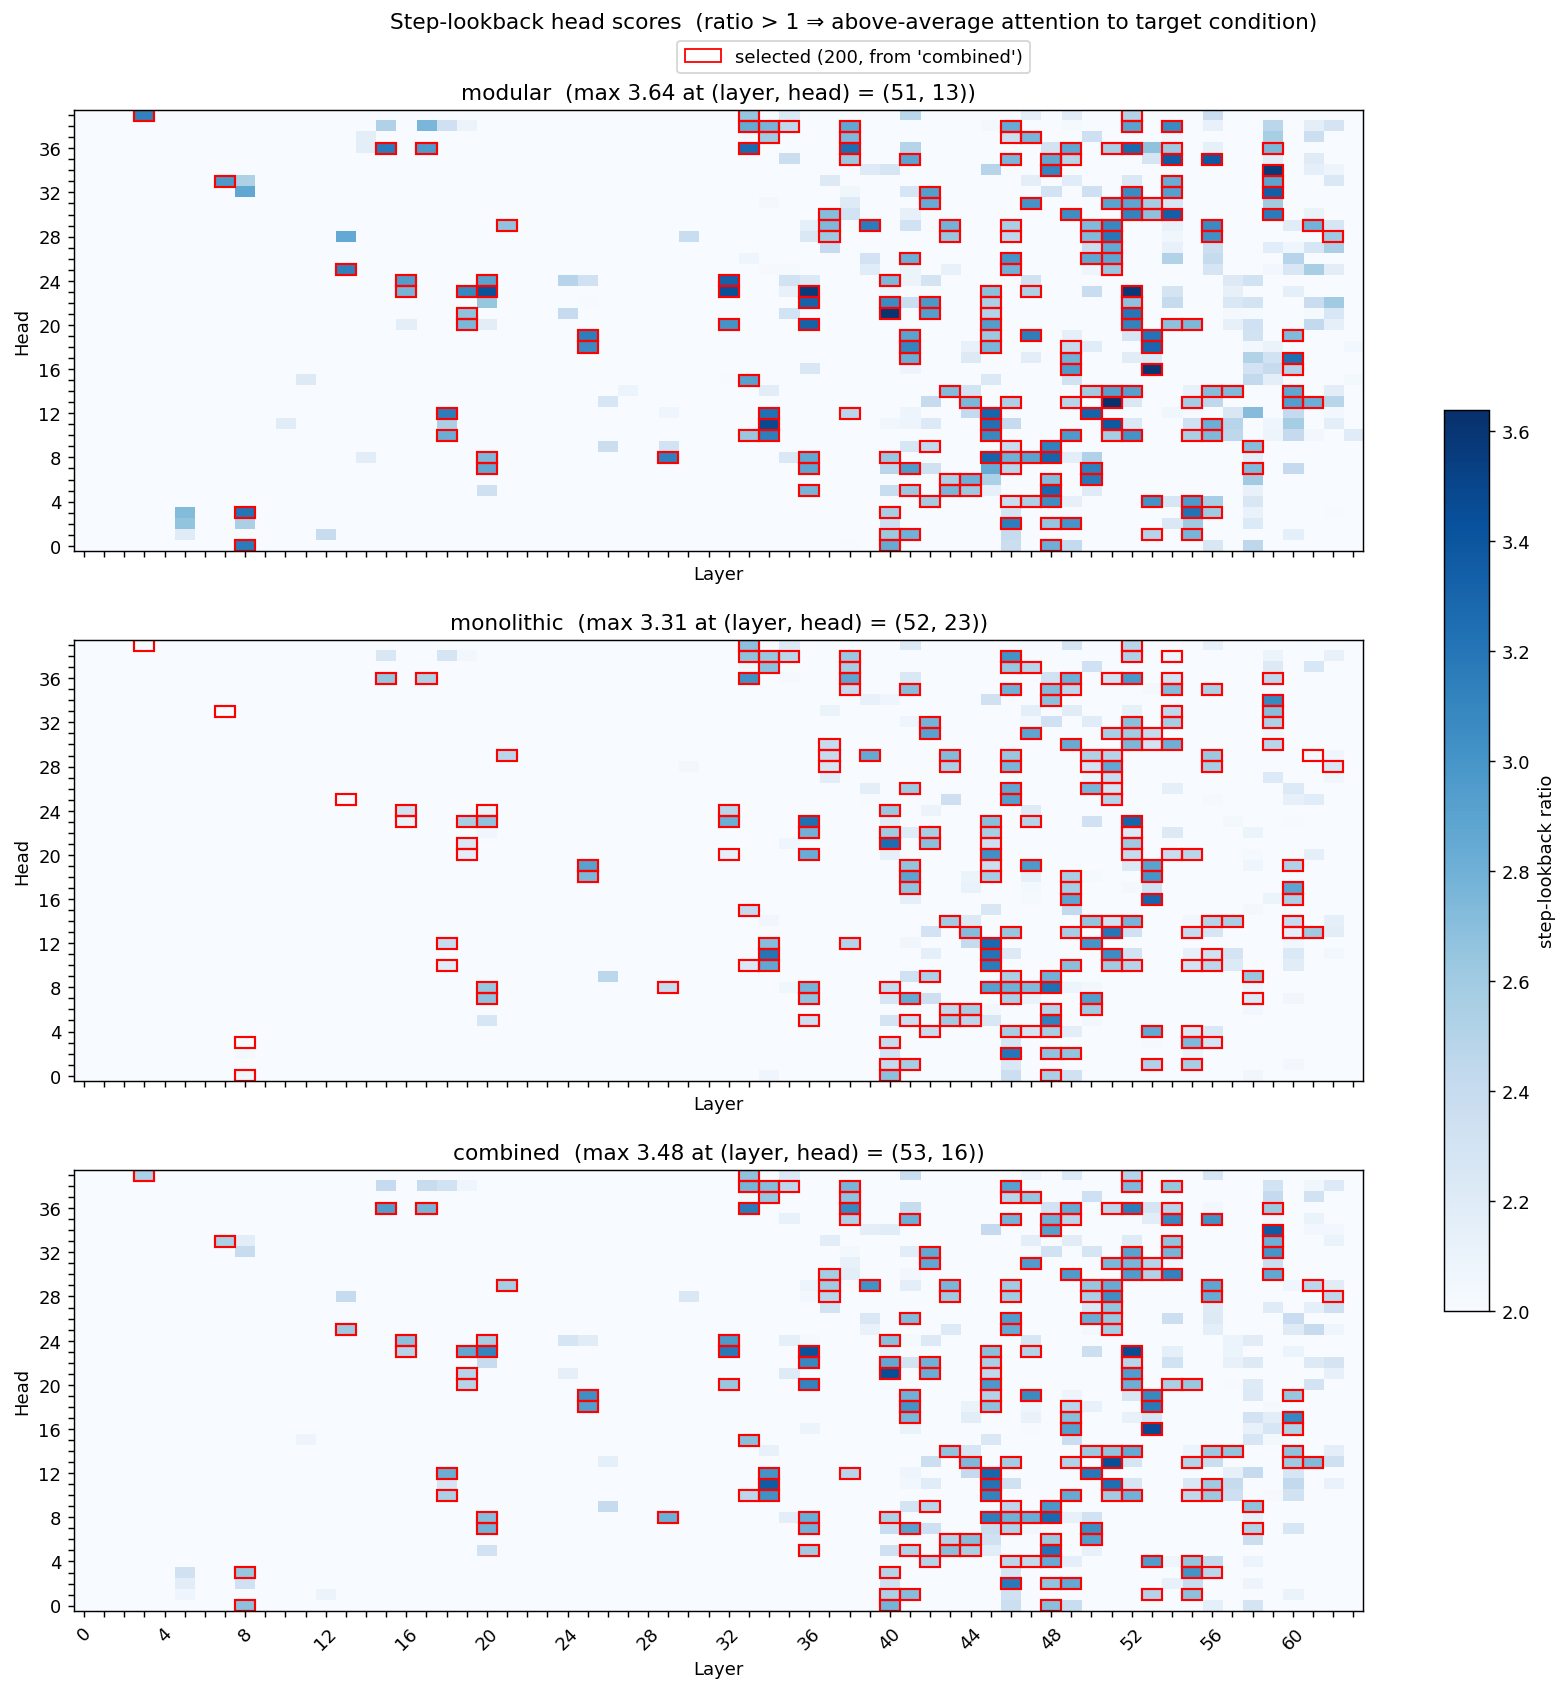

In [21]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scripts.clock.score_condition_heads import load_head_scores

# ── pick the scoring config to inspect ────────────────────────────────────────
Q_SPAN = 15
COMPARE_WITH = "mean"        # "mean" | "max"
# ──────────────────────────────────────────────────────────────────────────────
hs = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=Q_SPAN, compare_with=COMPARE_WITH)
scores_modular = hs["modular"]            # (n_layers, n_heads)
scores_monolithic = hs["monolithic"]
scores_combined = hs["combined"]
print(f"loaded {hs['dir']}")
print(f"  config: q_span={hs['metadata'].get('q_span')}  compare_with={hs['metadata'].get('compare_with')}")
for name, s in [("modular", scores_modular), ("monolithic", scores_monolithic),
                ("combined", scores_combined)]:
    print(f"  {name:11s} mean={s.mean():.3f}  max={s.max():.3f}")

# ── head selection (overlaid on the heatmaps) ─────────────────────────────────
SELECT_METHOD   = "topk"          # "topk" | "threshold"
TOP_N           = 200              # for topk
THRESHOLD       = 3.0            # for threshold (score ratio)
WHICH_SCORE_NAME = "combined"     # which panel drives selection
WHICH_SCORE = {"modular": scores_modular, "monolithic": scores_monolithic,
               "combined": scores_combined}[WHICH_SCORE_NAME]


def select_heads(score, method="topk", top_n=50, threshold=None):
    """Return [(layer, head), ...] selected from a (n_layers, n_heads) score map."""
    if method == "topk":
        flat = np.argsort(score, axis=None)[::-1][:top_n]
        pairs = (np.unravel_index(i, score.shape) for i in flat)
    elif method == "threshold":
        pairs = zip(*np.where(score >= threshold))
    else:
        raise ValueError(f"unknown method {method!r}")
    return [(int(l), int(h)) for l, h in pairs]


selected_heads = select_heads(WHICH_SCORE, SELECT_METHOD, TOP_N, THRESHOLD)
print(f"selected {len(selected_heads)} {len(selected_heads) / scores_combined.size * 100:.2f}% heads via {SELECT_METHOD} on '{WHICH_SCORE_NAME}'"
      + (f" (top {TOP_N})" if SELECT_METHOD == "topk" else f" (score ≥ {THRESHOLD})"))

panels = [("modular", scores_modular), ("monolithic", scores_monolithic),
          ("combined", scores_combined)]
# vmin = min(s.min() for _, s in panels)
vmin = 2.0
vmax = max(s.max() for _, s in panels)
n_layer_total, n_heads_total = scores_combined.shape

plt.rcParams["figure.dpi"] = 130
def get_ticks(ticks, skip=4):
    return [str(i) if i % skip == 0 else "" for i in ticks]

fig, axes = plt.subplots(len(panels), 1, figsize=(16, 5.0 * len(panels)), sharex=True)
last_im = None
for ax, (title, scores) in zip(axes, panels):
    im = ax.imshow(scores.T, aspect="auto", cmap="Blues", vmin=vmin, vmax=vmax,
                   interpolation="nearest", origin="lower")
    last_im = im
    # outline the selected heads (same set on every panel, from WHICH_SCORE)
    for (l, h) in selected_heads:
        ax.add_patch(plt.Rectangle((l - 0.5, h - 0.5), 1, 1, linewidth=1.2,
                                   edgecolor="red", facecolor="none"))
    argmax_lh = tuple(int(x) for x in np.unravel_index(scores.argmax(), scores.shape))
    ax.set_title(f"{title}  (max {scores.max():.2f} at (layer, head) = {argmax_lh})")
    ax.set_xlabel("Layer"); ax.set_ylabel("Head")
    ax.set_xticks(range(n_layer_total)); ax.set_xticklabels(get_ticks(range(n_layer_total)), rotation=45)
    ax.set_yticks(range(n_heads_total)); ax.set_yticklabels(get_ticks(range(n_heads_total)))

fig.colorbar(last_im, ax=axes.tolist(), shrink=0.6, label="step-lookback ratio")
sel_handle = mpatches.Patch(edgecolor="red", facecolor="none",
                            label=f"selected ({len(selected_heads)}, from '{WHICH_SCORE_NAME}')")
fig.legend(handles=[sel_handle], loc="upper center", ncol=1, bbox_to_anchor=(0.5, 0.92))
fig.suptitle("Step-lookback head scores  (ratio > 1 ⇒ above-average attention to target condition)", y=0.93)
plt.show()

In [22]:
from src.attention import AttentionInformation, show_interactive_attention


def load_attn(sample_name, modularity):
    base = os.path.join(CACHE_ROOT, "attn", modularity, sample_name)
    with np.load(os.path.join(base, "attn.npz"), allow_pickle=True) as d:
        attn = d["attn"]            # (n_layers, n_heads, seq, seq) float16, value-weighted
        tokens = list(d["tokens"])
    return attn, tokens


# ── inspect the selected heads (from the heatmap cell) ────────────────────────
ranked = sorted(selected_heads, key=lambda lh: WHICH_SCORE[lh[0], lh[1]], reverse=True)
print(f"{len(selected_heads)} selected heads on '{WHICH_SCORE_NAME}':")
for rank, (l, h) in enumerate(ranked[:20], start=1):
    print(f"  {rank:2d}.  L{l:2d} H{h:2d}   score={WHICH_SCORE[l, h]:.3f}")
if len(ranked) > 20:
    print(f"  ... (+ {len(ranked) - 20} more)")

200 selected heads on 'combined':
   1.  L53 H16   score=3.478
   2.  L52 H23   score=3.464
   3.  L40 H21   score=3.452
   4.  L51 H13   score=3.451
   5.  L36 H23   score=3.422
   6.  L59 H34   score=3.364
   7.  L34 H11   score=3.358
   8.  L45 H12   score=3.293
   9.  L48 H 8   score=3.277
  10.  L51 H11   score=3.246
  11.  L45 H11   score=3.222
  12.  L48 H 5   score=3.217
  13.  L50 H12   score=3.181
  14.  L32 H23   score=3.175
  15.  L53 H18   score=3.168
  16.  L33 H36   score=3.167
  17.  L46 H 2   score=3.166
  18.  L52 H36   score=3.150
  19.  L45 H 8   score=3.143
  20.  L54 H30   score=3.113
  ... (+ 180 more)


In [23]:
# scores = WHICH_SCORE.reshape(WHICH_SCORE.shape[0] * WHICH_SCORE.shape[1])
# scores = sorted(scores, reverse=True)

# plt.plot(scores[:50])

In [24]:
### ---- demo sample for the attention viz ----
VIZ_SAMPLE = DEMO_SAMPLE
VIZ_MODULARITY = DEMO_MODULARITY
### -----------------------------------------
attn_arr, tokens = load_attn(VIZ_SAMPLE, VIZ_MODULARITY)
print(f"{VIZ_SAMPLE} · {VIZ_MODULARITY}:  attn {attn_arr.shape} dtype={attn_arr.dtype}  ({len(tokens)} tokens)")
attn_info = AttentionInformation(tokenized_prompt=tokens, attention_matrices=attn_arr)

# Skip the chat-template prefix so the viz starts at the user query.
start_from = 0
try:
    first_user = next(i for i, t in enumerate(tokens) if "user" in t.replace("＜", "<"))
    start_from = max(0, first_user - 1)
except StopIteration:
    pass

show_interactive_attention(
    attn_info=attn_info,
    selected_heads=selected_heads,
    start_from=start_from,
    agg="mean",
    normalize="row_max",
    cmap="Blues",
    title=f"{VIZ_SAMPLE} · {VIZ_MODULARITY} · {len(selected_heads)} selected heads (value-weighted)",
    height=None,
)

cond_0001 · monolithic:  attn (64, 40, 301, 301) dtype=float16  (301 tokens)


'<!DOCTYPE html>\n<html><head><meta charset="utf-8"><title>cond_0001 · monolithic · 200 selected heads (value-weighted)</title>\n<style>\n #iaviz-717abd98 { font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Helvetica, Arial, sans-serif;\n            background: #fafafa; color: #111; padding: 12px; border-radius: 6px; }\n #iaviz-717abd98 h2 { margin: 4px 0 6px 0; font-size: 16px; font-weight: 600; color: #111; }\n #iaviz-717abd98 .meta { color: #555; font-size: 12px; margin-bottom: 10px; }\n #iaviz-717abd98 .head-list { color: #777; font-size: 11px; margin-bottom: 14px; font-family: monospace; }\n #iaviz-717abd98 .tokens {\n   font-family: ui-monospace, "SF Mono", Menlo, Consolas, monospace;\n   font-size: 13px;\n   line-height: 1.85;\n   background: #fff;\n   border: 1px solid #ddd;\n   border-radius: 6px;\n   padding: 14px 16px;\n   white-space: pre-wrap;\n   word-break: break-word;\n }\n #iaviz-717abd98 .tok {\n   display: inline-block;\n   padding: 2px 4px;\n   mar

## 3. Run a few live generations

Load the `ConditionDataset` and generate greedy completions with the full model —
the same prompt construction the build script uses.

In [25]:
from src.goals.condition_data import ConditionDataset
from src.goals.functional import apply_chat_template, supports_chat_template
from src.tokens import prepare_input

DATASET_PATH = os.path.join(env_utils.DEFAULT_DATA_DIR, "multistep", "condition_check_python.json")
cond_ds = ConditionDataset.load(DATASET_PATH)
print(f"loaded {len(cond_ds.samples)} samples from {DATASET_PATH}")


def build_prompt(sample):
    instr = sample.render_instruction()
    stub = sample.render_code_stub()
    if supports_chat_template(mt):
        return apply_chat_template(mt=mt, user_query=instr.strip(), incomplete_code=stub)
    return instr + "\nAnswer:\n" + stub


@torch.no_grad()
def generate(prompt, max_new_tokens=512):
    pad_id = mt.tokenizer.pad_token_id or mt.tokenizer.eos_token_id
    inputs = prepare_input(prompts=[prompt], tokenizer=mt)
    plen = inputs["input_ids"].shape[1]
    out = mt._model.generate(
        input_ids=inputs["input_ids"], attention_mask=inputs["attention_mask"],
        max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=pad_id,
    )
    return mt.tokenizer.decode(out[0, plen:], skip_special_tokens=True)

loaded 1000 samples from /disk/u/arnab/Codes/Projects/goals/data/multistep/condition_check_python.json


In [ ]:
# # Pick a sample and generate.
# s = cond_ds.samples[5]
# print(f"{s.name}  lang={s.lang}  modularity={s.modularity}  ({s.spec.num_conditions} conditions)\n")
# prompt = build_prompt(s)
# gen = generate(prompt, max_new_tokens=512)
# print(gen)

cond_0002__python__monolithic  lang=python  modularity=monolithic  (5 conditions)

    a = n % 2 != 0
    b = int(n**0.5)**2 == n
    c = n % 2 == 0
    d = n % 2 == 0
    e = sum(int(digit) for digit in str(n)) > 15
    print(f"Odd: {a}, Perfect Square: {b}, Even (c): {c}, Even (d): {d}, Digit Sum > 15: {e}, All: {a and b and c and d and e}")
</code>


## 4. Causal test — restrict the gaze heads to one step's spec

Sufficiency test for the gaze→implement chain. At `b = ` (where the LM normally
implements **condition `CURRENT_STEP`**), restrict *only the selected gaze heads*
(query rows ≥ `q_start`) so that — across the whole context — they may attend to
**nothing but cond `TARGET_STEP`'s spec span**. Everything else (the other specs,
the instruction, the code, the sink) gets `−∞`; softmax renormalizes over the
target span, so the LM itself sets the weights *within* it (no fabricated scores).

Setting: **monolithic** (the inline RHS encodes the predicate, so gaze is
load-bearing). Readout: eyeball the generated `b`-RHS against the spec lines.

Findings so far (`cond_0001`, b→cond2): the redirect only bites once ~`N_GAZE≈300`
heads (~12%) are restricted — the signal is **distributed**, not a sparse set —
and **matched-count random heads produce no change**, so the effect is
gaze-specific, not generic content-injection. Requires `selected_heads` from §2
(set §2 `TOP_N ≥ N_GAZE`).

In [27]:
import re
import random as _random
from collections import defaultdict

import torch
from src.functional import get_module_nnsight
from src.tokens import prepare_input

N_HEADS = mt.model.config.num_attention_heads


def group_heads(heads):
    d = defaultdict(list)
    for l, h in sorted(heads):                  # ascending layer = nnsight execution order
        d[l].append(h)
    return dict(d)


def random_heads_like(selected, seed=0):
    rng = _random.Random(seed)
    sel = set(selected)
    pool = [(l, h) for l in range(mt.n_layer) for h in range(N_HEADS) if (l, h) not in sel]
    return rng.sample(pool, len(selected))


def spec_line_spans(lab):
    """Full numbered spec-line token span per condition (prompt_token_range), or None."""
    return [tuple(sl.prompt_token_range) if sl.prompt_token_range else None for sl in lab.labels]


def cut_after_assignment(generation, var):
    m = re.search(rf"(?m)^\s*{re.escape(var)}\s*=", generation)
    if m is None:
        raise ValueError(f"no '{var} =' assignment line found in generation")
    return m.end()


def keys_outside_span(span, seq):
    """All key indices NOT in `span` — i.e. mask everything except `span`."""
    keep = set(range(span[0], span[1]))
    return [k for k in range(seq) if k not in keep]


@torch.no_grad()
def generate_with_head_attn_mask(prefill, layer_to_heads, masked_keys, q_start, max_new=30):
    """Greedy non-cached decode. For each layer→[heads], add −∞ to the pre-softmax
    attention scores at query rows ≥ q_start over key positions `masked_keys`, for
    those heads only. layer_to_heads={} ⇒ unmodified baseline."""
    ids = prepare_input(prompts=[prefill], tokenizer=mt, add_special_tokens=False)["input_ids"]
    mk = torch.tensor(sorted(masked_keys), dtype=torch.long)
    gen = []
    for _ in range(max_new):
        seq = ids.shape[1]
        kvec = torch.zeros(seq)
        if mk.numel():
            kvec[mk] = float("-inf")
        with mt.trace({"input_ids": ids, "attention_mask": torch.ones_like(ids)},
                      scan=False, validate=False):
            for L in sorted(layer_to_heads):            # ascending = nnsight execution order
                am = get_module_nnsight(mt, mt.attn_module_name_format.format(L))
                sm = am.source.attention_interface_0.source.nn_functional_softmax_0
                km = torch.zeros(1, N_HEADS, seq, seq)
                for h in layer_to_heads[L]:
                    km[0, h, q_start:, :] += kvec
                sm.input = sm.input + km.to(device=sm.input.device, dtype=sm.input.dtype)
            logits = mt.output.logits[:, -1, :].save()
        nxt = int(logits[0].argmax(-1))
        if nxt == mt.tokenizer.eos_token_id:
            break
        gen.append(nxt)
        ids = torch.cat([ids, torch.tensor([[nxt]], device=ids.device)], dim=1)
    return mt.tokenizer.decode(gen, skip_special_tokens=True)

In [28]:
from rich.markup import escape

### ---- restrict-to-target demo (monolithic) ----
RDX_SAMPLE = "cond_0003"     # monolithic sample with ≥3 distinct-predicate conditions
ASSIGN_VAR = "b"             # assignment we intervene at  (a=cond0, b=cond1, c=cond2, …)
TARGET_STEP = 2              # restrict the gaze to this condition's spec span
N_GAZE = 200                 # # of top gaze heads to restrict (needs §2 TOP_N ≥ N_GAZE)
MAX_NEW = 30
### -----------------------------------------------
CURRENT_STEP = ord(ASSIGN_VAR) - ord("a")
gaze = selected_heads[:N_GAZE]

lab, comp = load_labeled(RDX_SAMPLE, "monolithic")
spans = spec_line_spans(lab)
cut = cut_after_assignment(lab.generation, ASSIGN_VAR)
prefill = lab.full_prompt + lab.generation[:cut]
ids = prepare_input(prompts=[prefill], tokenizer=mt, add_special_tokens=False)["input_ids"]
seq = ids.shape[1]
q_start = seq - 1                          # last prefill token writes the first RHS token
target_span = spans[TARGET_STEP]
restrict_mask = keys_outside_span(target_span, seq)

l2h = group_heads(gaze)
r2h = group_heads(random_heads_like(gaze, seed=0))

rich_print(f"[demo config] sample={RDX_SAMPLE}  assign_var='{ASSIGN_VAR}'  N_GAZE={len(gaze)}")
print(f"restrict gaze → cond {TARGET_STEP} span {tuple(target_span)} = "
      f"{mt.tokenizer.decode(ids[0, target_span[0]:target_span[1]])!r}\n")
for i, sl in enumerate(lab.labels):
    tag = "  ← TARGET" if i == TARGET_STEP else ("  ← current" if i == CURRENT_STEP else "")
    print(f"  cond {i}: {sl.step_text}{tag}")
print(f"\nnatural cached b-line:  {lab.generation[cut:cut+70].splitlines()[0]!r}")

base  = generate_with_head_attn_mask(prefill, {},  restrict_mask, q_start, MAX_NEW)
rich_print(f"\n[baseline   no mask        ]  {ASSIGN_VAR} =[sea_green1]{escape(base)!r}[/]")
restr = generate_with_head_attn_mask(prefill, l2h, restrict_mask, q_start, MAX_NEW)
rich_print(f"[restrict   gaze⊂cond{TARGET_STEP}     ]  {ASSIGN_VAR} =[salmon1]{escape(restr)!r}[/]")
ctrl  = generate_with_head_attn_mask(prefill, r2h, restrict_mask, q_start, MAX_NEW)
rich_print(f"[control    {len(gaze)} random heads]  {ASSIGN_VAR} =[plum1]{escape(ctrl)!r}[/]")

sample=cond_0003  assign_var='b'  N_GAZE=200

restrict gaze → cond 2 span (93, 106) = ' n is between 0 and 500 (inclusive)\n'

  cond 0: the sum of n's digits is greater than 15
  cond 1: n is a prime number  ← current
  cond 2: n is between 0 and 500 (inclusive)  ← TARGET
  cond 3: n is greater than or equal to 0
  cond 4: n is greater than or equal to 0

natural cached b-line:  ' all(n % i != 0 for i in range(2, int(n**0.5) + 1)) if n > 1 else Fals'


b =' all(n % i != 0 for i in range(2, int(n**0.5) + 1)) if n > 1'

b =' 0 <= n <= 500\n    c = 0 <= n <= 500\n    d = 0 <= n'

b =' all(n % i != 0 for i in range(2, int(n**0.5) + 1)) if n > 1'

In [29]:
# ### ---- directionality sweep: restrict the gaze to each step in turn ----
# # Strongest evidence: the LM implements *whichever* step we restrict the gaze to.
# rich_print(f"sample {RDX_SAMPLE} · '{ASSIGN_VAR} =' (natural = cond {CURRENT_STEP}) · "
#            f"restrict {len(gaze)} gaze heads →")
# for t in range(len(lab.labels)):
#     if spans[t] is None:
#         continue
#     mask_t = keys_outside_span(spans[t], seq)
#     out = generate_with_head_attn_mask(prefill, l2h, mask_t, q_start, MAX_NEW)
#     mark = "  (natural)" if t == CURRENT_STEP else ""
#     rich_print(f"  gaze⊂cond {t} ({lab.labels[t].step_text[:34]:34s}){mark}:  "
#                f"{ASSIGN_VAR} =[grey70]{escape(out)!r}[/]")